# Reproducing the Overcomplete Speech Experiment with the Same Data as the Paper

We reproduce the blind separation of more sources than observations (three sources of natural speech, two observations) in Section 4 of Girolami (2001), using data believed to be the same as in the paper.

## Data
We use `speech.mat` to reproduce the experiments of Girolami (2001) and Lee et al. (1999), which use the same three sources of natural speech and the same mixing matrix.

- Sources: 3 utterances from the same TIMIT speaker (8 kHz, 8 bit)
- Mixing matrix:

$$
A=
\begin{bmatrix}
1 & 1/\sqrt{2} & 1/\sqrt{2}\\
0 & 1/\sqrt{2} & -1/\sqrt{2}
\end{bmatrix}
$$

The original host `cnl.salk.edu/~tewon/Over` is gone, so we use the `speech.mat` that was bundled with the Matlab toolbox `icaMF` by Højen-Sørensen et al. (2002).

However, the `icaMF` distribution site is also gone, so we retrieve it from the Wayback Machine.

```bash
curl -L -o icaMF.zip "http://web.archive.org/web/2005id_/http://mole.imm.dtu.dk:80/toolbox/ica/mf/icaMF.zip"
```

Place the downloaded `speech.mat` in the `data` directory.

## Conditions
- As in Figure 3 of the paper, we use 10,000 samples of the original sources and add no noise to the mixtures (same as the icaMF demo; adding noise equivalent to 8-bit quantization barely changed the results).
- As in the paper, the EM procedure is randomly initialized and stopped after 10 parameter updates, with the variational parameters updated twice in each pass (`n_xi_updates=2`). For comparison, we also show runs to convergence (at most 500 updates).
- The paper reports the result of a single run only, so we show the results of 5 runs with different random seeds.
- The signal-to-noise ratio (SNR) of each inferred source is $10\log_{10}\|s\|^2/\|s-\alpha\hat s\|^2$ ($\alpha$ is the least-squares scale, correcting for the shrinkage of the posterior mean).

In [1]:
import sys
import itertools
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio

from ocica import OvercompleteICA
from ocica import align_sources, match_components, source_snr

plt.rcParams["figure.dpi"] = 100

mat = sio.loadmat("../data/speech.mat")
A = mat["A"]
S = mat["S"].T[:10000]  # (samples, sources)
X = S @ A.T  # observations
print("A =\n", A.round(4))
print("S:", S.shape, " X:", X.shape)

# SNR values in dB reported in Table 1 of Girolami (2001)
paper = pd.DataFrame(
    {"Girolami (2001) variational EM": [26, 18, 24], "Lee et al. (1999) gradient-based method": [20, 17, 21]},
    index=["s1", "s2", "s3"],
)

A =
 [[ 1.      0.7071  0.7071]
 [ 0.      0.7071 -0.7071]]
S: (10000, 3)  X: (10000, 2)


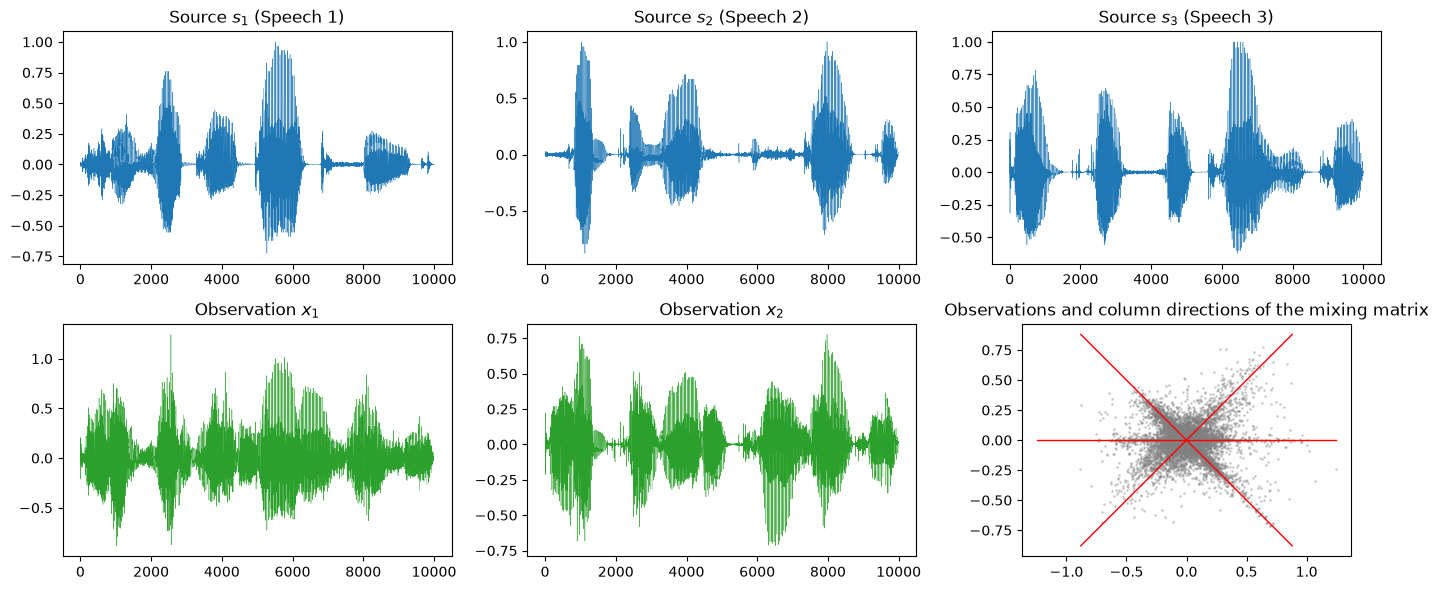

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for l in range(3):
    axes[0, l].plot(S[:, l], lw=0.3)
    axes[0, l].set_title(f"Source $s_{l + 1}$ (Speech {l + 1})")
for m in range(2):
    axes[1, m].plot(X[:, m], lw=0.3, color="C2")
    axes[1, m].set_title(f"Observation $x_{m + 1}$")
ax = axes[1, 2]
ax.scatter(X[:, 0], X[:, 1], s=1, alpha=0.3, color="gray")
for l in range(3):
    d = A[:, l] / np.linalg.norm(A[:, l]) * np.abs(X).max()
    ax.plot([-d[0], d[0]], [-d[1], d[1]], "r-", lw=1)
ax.set_aspect("equal")
ax.set_title("Observations and column directions of the mixing matrix")
plt.tight_layout()
plt.show()

## 1. Estimation under the Paper's Conditions

The column norm is the length of each column of the estimated mixing matrix (reordered to match the true order). A column that is nearly 0 means the corresponding source was missed.

In [3]:
def evaluate(model, X, S):
    """Align the estimated sources with the true ones and compute metrics.

    Parameters
    ----------
    model : OvercompleteICA
        Fitted estimator.
    X : ndarray of shape (n_samples, n_features)
        Observed variables.
    S : ndarray of shape (n_samples, n_components)
        True latent variables.

    Returns
    -------
    angles : ndarray of shape (n_components,)
        Angle errors of the mixing columns in degrees.
    norms : ndarray of shape (n_components,)
        Norms of the estimated mixing columns.
    snr : ndarray of shape (n_components,)
        SNR of the inferred sources in dB.
    S_al : ndarray of shape (n_samples, n_components)
        Estimated sources aligned with ``S``.
    """
    perm, signs, angles = match_components(A, model.mixing_)
    S_al = align_sources(model.transform(X), perm, signs)
    norms = np.linalg.norm(model.mixing_, axis=0)[perm]
    return angles, norms, source_snr(S, S_al), S_al


rows, recovered = [], {}
for max_iter in (10, 500):
    for seed in range(5):
        ica = OvercompleteICA(n_components=3, n_xi_updates=2, max_iter=max_iter, random_state=seed).fit(X)
        angles, norms, snr, S_al = evaluate(ica, X, S)
        recovered[max_iter, seed] = S_al
        rows.append({"updates": max_iter, "seed": seed,
                     **{f"angle error s{l + 1}": angles[l] for l in range(3)},
                     **{f"column norm s{l + 1}": norms[l] for l in range(3)},
                     **{f"SNR s{l + 1}": snr[l] for l in range(3)}})
result = pd.DataFrame(rows).set_index(["updates", "seed"])
result.round(2)

angle error s1  angle error s2  angle error s3  column norm s1  \
updates seed                                                                   
10      0               4.46            9.00           12.31            0.12   
        1              12.28            1.98            7.18            0.16   
        2              29.19           12.53            3.23            0.01   
        3               2.48           45.21           12.91            0.20   
        4              21.55           10.29           53.48            0.20   
500     0               3.65            7.59            5.65            0.00   
        1              13.23           11.16            2.80            0.04   
        2              33.70           13.18            2.06            0.00   
        3               0.18           53.35           25.52            0.21   
        4              31.39            0.11           46.84            0.19   

              column norm s2  column norm s3  SNR s1  SNR s2  SNR s3  
updates seed                                                          
10      0               0.14            0.16    4.94    7.82    7.84  
        1               0.14            0.12    4.49    8.39    9.39  
        2               0.17            0.17    1.71    5.48    6.63  
        3               0.15            0.02    2.59    3.15    3.64  
        4               0.15            0.02    1.80    5.97    2.66  
500     0               0.16            0.17    1.97    5.62    6.16  
        1               0.15            0.16    2.46    5.45    6.53  
        2               0.16            0.17    1.23    5.29    6.51  
        3               0.15            0.00    2.55    2.77    2.06  
        4               0.16            0.00    1.40    6.07    2.16

## 2. Upper Bound Using the True Mixing Matrix

To separate whether the failure comes from estimating the mixing matrix or from something earlier, we infer the sources using the true $A$.

- **EM (start from truth)**: Initialize with the true $A$ (scaled by the standard deviations of the sources to match the model's unit variance) and run 10 parameter updates as in the paper.
- **L1 minimum (true $A$)**: Among the solutions satisfying $\mathbf x=A\mathbf s$ without noise, the one that minimizes $\sum_l |s_l|/\sigma_l$. This is the MAP estimate under a Laplacian prior and corresponds to the estimation method of Lee et al. (1999). For 2×3, the minimum is attained by one of the pairs of 2 columns.
- **One source per time point (true $A$)**: Assume that only the source whose column direction is closest is active at each time point (the method of Lin et al.; Lee et al. report an SNR 2–7 dB lower than their own method).

In [4]:
sd = S.std(axis=0)
upper = {}

ica_true = OvercompleteICA(n_components=3, n_xi_updates=2, max_iter=10, w_init=A * sd).fit(X)
upper["EM (start from truth, 10 updates)"] = evaluate(ica_true, X, S)[2]

S_l1, best = np.zeros_like(S), np.full(len(S), np.inf)
for pair in itertools.combinations(range(3), 2):
    Sp = np.zeros_like(S)
    Sp[:, pair] = np.linalg.solve(A[:, pair], X.T).T
    l1 = np.abs(Sp / sd).sum(axis=1)
    S_l1[l1 < best] = Sp[l1 < best]
    best = np.minimum(best, l1)
upper["L1 minimum (true A)"] = source_snr(S, S_l1)

proj = X @ A  # columns have unit norm
k = np.abs(proj).argmax(axis=1)
S_one = np.zeros_like(S)
S_one[np.arange(len(S)), k] = proj[np.arange(len(S)), k]
upper["One source per time point (true A)"] = source_snr(S, S_one)

snr_cols = [f"SNR s{l + 1}" for l in range(3)]
summary = pd.concat([
    paper.T,
    pd.DataFrame(upper, index=paper.index).T,
    result.loc[10, snr_cols].median().rename(lambda c: c[4:]).to_frame("10 updates as in the paper (median of 5 runs)").T,
    result.loc[10, snr_cols].max().rename(lambda c: c[4:]).to_frame("10 updates as in the paper (max of 5 runs)").T,
])
print("SNR [dB]")
summary.round(1)

SNR [dB]


,s1,s2,s3
Girolami (2001) variational EM,26.0,18.0,24.0
Lee et al. (1999) gradient-based method,20.0,17.0,21.0
"EM (start from truth, 10 updates)",5.7,8.5,9.1
L1 minimum (true A),6.0,9.5,10.0
One source per time point (true A),4.8,7.4,8.0
10 updates as in the paper (median of 5 runs),2.6,6.0,6.6
10 updates as in the paper (max of 5 runs),4.9,8.4,9.4


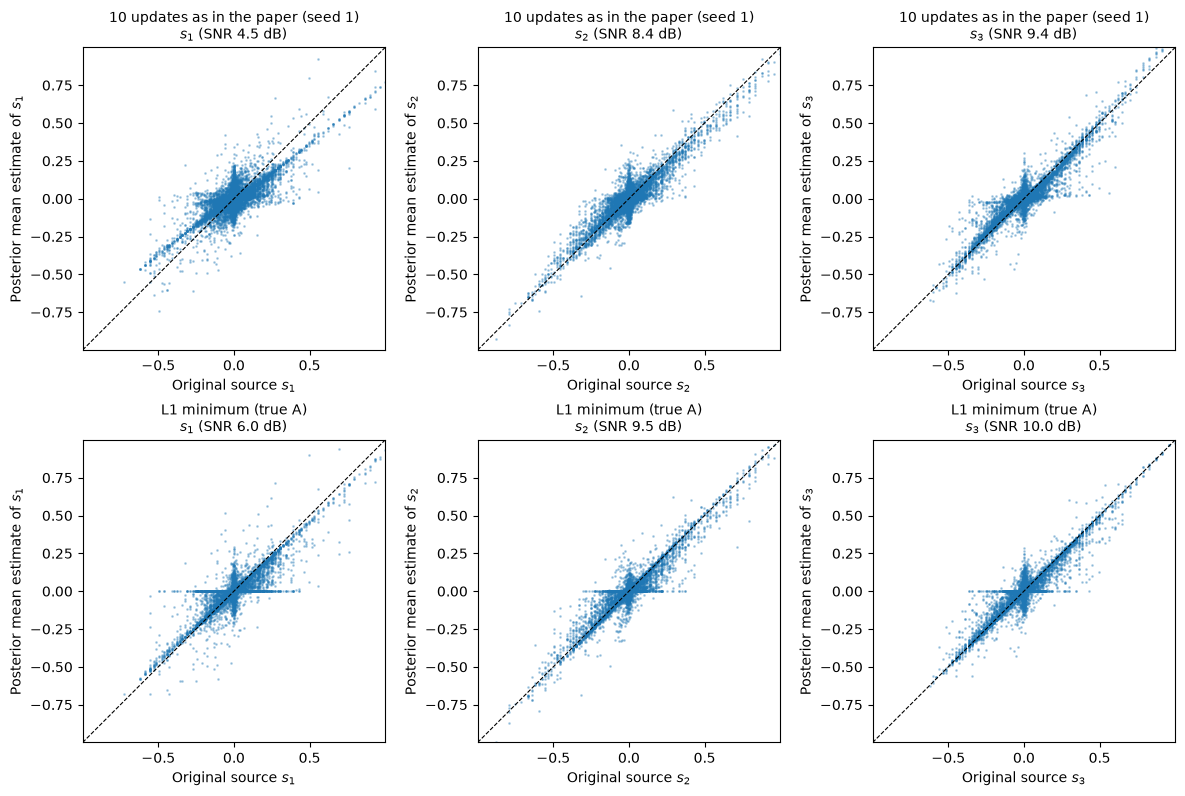

In [5]:
# Scatter plots of original sources vs. estimates: the 10-update run with the largest total SNR as in the paper, and L1 minimum (true A)
best_seed = result.loc[10, snr_cols].sum(axis=1).idxmax()
panels = [(f"10 updates as in the paper (seed {best_seed})", recovered[10, best_seed]), ("L1 minimum (true A)", S_l1)]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
lim = np.abs(S).max()
for i, (name, Sh) in enumerate(panels):
    snr = source_snr(S, Sh)
    for l in range(3):
        ax = axes[i, l]
        # show the estimates scaled to the original sources by least squares
        alpha = (S[:, l] @ Sh[:, l]) / (Sh[:, l] @ Sh[:, l])
        ax.scatter(S[:, l], alpha * Sh[:, l], s=1, alpha=0.3)
        ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)
        ax.set_aspect("equal")
        ax.set_xlabel(f"Original source $s_{l + 1}$")
        ax.set_ylabel(f"Posterior mean estimate of $s_{l + 1}$")
        ax.set_title(f"{name}\n$s_{l + 1}$ (SNR {snr[l]:.1f} dB)", fontsize=10)
plt.tight_layout()
plt.show()

## 3. Waveform Comparison

Following Figure 3 of the paper, the top row shows the original sources and the bottom row shows the posterior mean estimates of the sources, arranged left to right as $s_1, s_2, s_3$.
The estimates come from the run with the largest total SNR among the 10-update runs as in the paper, scaled to the original sources by least squares. The vertical axis range is shared within each column.

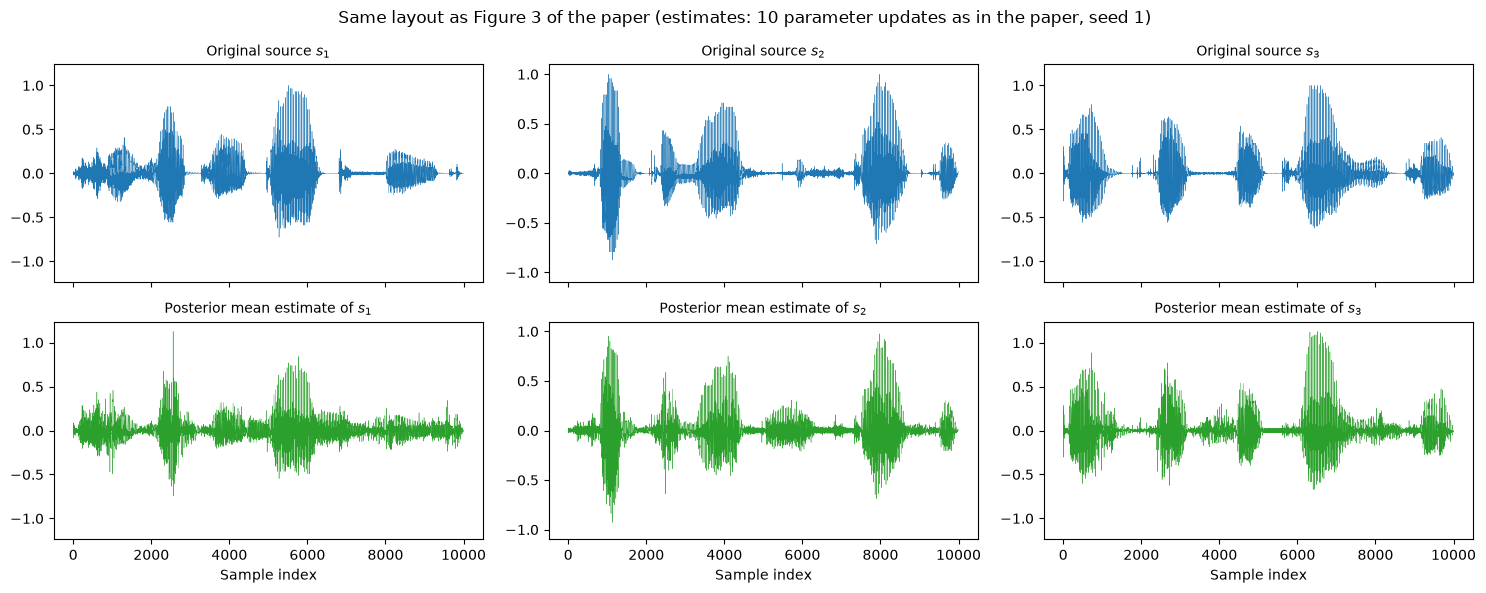

In [6]:
S_best = recovered[10, best_seed]
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
for l in range(3):
    alpha = (S[:, l] @ S_best[:, l]) / (S_best[:, l] @ S_best[:, l])
    lim = 1.1 * max(np.abs(S[:, l]).max(), np.abs(alpha * S_best[:, l]).max())
    axes[0, l].plot(S[:, l], lw=0.3, color="C0")
    axes[0, l].set_title(f"Original source $s_{l + 1}$", fontsize=10)
    axes[1, l].plot(alpha * S_best[:, l], lw=0.3, color="C2")
    axes[1, l].set_title(f"Posterior mean estimate of $s_{l + 1}$", fontsize=10)
    for ax in axes[:, l]:
        ax.set_ylim(-lim, lim)
    axes[1, l].set_xlabel("Sample index")
fig.suptitle(f"Same layout as Figure 3 of the paper (estimates: 10 parameter updates as in the paper, seed {best_seed})")
plt.tight_layout()
plt.show()